In [50]:
# Load the libraries. "as pd" gives each a short nickname, 
# so we write pd instead of pandas.
import pandas as pd  # tables of data (called DataFrames)
import numpy as np  # fast math on numbers
import matplotlib.pyplot as plt # drawing charts
import seaborn as sns # nicer-looking charts, built on matplotlib
# Read the CSV file into a table called df (short for DataFrame).
# "../" means go up one folder: from notebooks/ 
# to the project, then into data/.
df = pd.read_csv("../data/KaggleV2-May-2016.csv")
# shape = (number of rows, number of columns). 
# The last line of a cell is shown automatically.
df.shape

(110527, 14)

In [51]:
# Show the first 5 rows, so you can see what each column looks like.
# Try df.head(10) for 10 rows, or df.tail() for the last 5.
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [52]:
# For every column: its name, how many values are 
# --filled in (non-null), and its type.
# Types: int64 = whole numbers, float64 = decimals, 
# --str/object = text.
# If every column says 110527 non-null, 
# --there are no missing values.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 11.8 MB


In [53]:
# rename() changes column names. 
# --The dictionary maps {"old name": "new name"}.
# We use lowercase_with_underscores (snake_case): 
# --the Python convention, and easier to type.
# It also fixes the original typos: Hipertension, Handcap
df = df.rename(columns={
    "PatientId": "patient_id",
    "AppointmentID": "appointment_id",
    "Gender": "gender",
    "ScheduledDay": "scheduled_day", 
    # when the appointment was booked
    "AppointmentDay": "appointment_day",   
    # the day of the appointment itself
    "Age": "age",
    "Neighbourhood": "neighbourhood",
    "Scholarship": "scholarship",          
    # 1 = enrolled in a Brazilian welfare program
    "Hipertension": "hypertension",
    "Diabetes": "diabetes",
    "Alcoholism": "alcoholism",
    "Handcap": "handicap",
    "SMS_received": "sms_received",        
    # 1 = got an SMS reminder
    "No-show": "no_show",                  
    # "Yes" = the patient MISSED the appointment
})

In [54]:
# (df["no_show"] == "Yes") checks every row: True if "Yes", False if "No".
# .astype(int) turns True into 1 and False into 0. Models need numbers, not words.
df["no_show"] = (df["no_show"] == "Yes").astype(int)
# The mean of a 0/1 column = the share of 1s = the no-show rate.
df["no_show"].mean()

np.float64(0.20193255946510807)

In [55]:
# Convert the date columns from text to real dates, 
# so we can subtract them.
df["scheduled_day"] = pd.to_datetime(df["scheduled_day"])
df["appointment_day"] = pd.to_datetime(df["appointment_day"])

# Lead time = appointment date minus booking date, 
# -in whole days.
# .dt.normalize() drops the time of day (ScheduledDay has 
# -hours and minutes;AppointmentDay is always midnight), 
# -so we compare calendar days only.
# .dt.days turns the time difference into a plain number of days.

df["lead_days"] = ( 
    df["appointment_day"].dt.normalize() - 
df["scheduled_day"].dt.normalize()
).dt.days
# describe() gives a quick summary: count, mean, min, 
# -max and percentiles.
df["lead_days"].describe()

count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: lead_days, dtype: float64

In [56]:
# (df["lead_days"] < 0) is True for each impossible row 
# -(booked AFTER the appointment).
# .sum() counts the Trues, because True counts as 1.
print("Negative leadtimes:", (df["lead_days"] < 0).sum())

# Same idea: ages below 0 are data-entry errors.
print("Ages below 0:", (df["age"] < 0).sum())

# The earliest and latest appointment dates: how much time 
# -the data covers

print("Appointment dates:", df["appointment_day"].min(), "to",
df["appointment_day"].max())

Negative leadtimes: 5
Ages below 0: 1
Appointment dates: 2016-04-29 00:00:00+00:00 to 2016-06-08 00:00:00+00:00


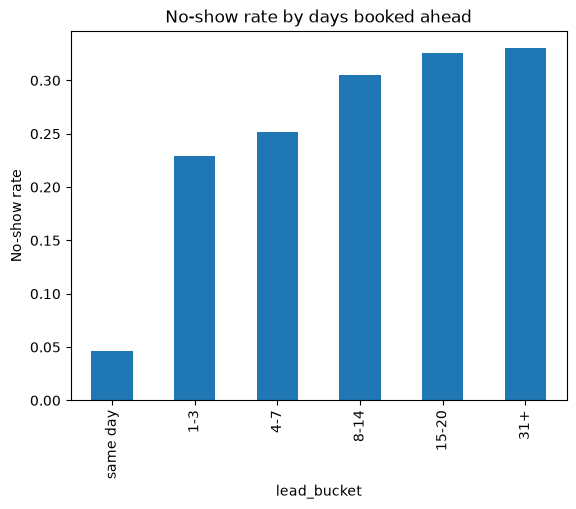

In [57]:
# Group lead times into buckets. Each bucket covers 
# -(left, right]:
# (-1, 0] = same day, (0, 3] = 1-3 days, (3, 7] = 4-7 days, 
# -and so on.
bins = [-1, 0, 3, 7, 14, 30, 200]
labels = ["same day", "1-3", "4-7", "8-14", "15-20", "31+"]

# pd.cut() puts each row's lead_days into the matching bucket.
df["lead_bucket"] = pd.cut(df["lead_days"], bins=bins, 
labels=labels)

# groupby() splits rows by bucket; .mean() of no_show gives 
# -each bucket's no-show rate.
# observed=True skips empty buckets.
rate = df.groupby("lead_bucket", observed=True)["no_show"].mean()

# Draw it as a bar chart.
rate.plot(kind="bar", title="No-show rate by days booked ahead")
plt.ylabel("No-show rate")
plt.show() # display the chart under the cell

In [58]:
#do SMS reminders make people miss appointments?
# No-show rate for patients without an SMS (0) vs with one (1).
df.groupby("sms_received")["no_show"].mean()

sms_received
0    0.167033
1    0.275745
Name: no_show, dtype: float64

In [59]:
# Same comparison, but separately inside each lead-time bucket.
# Grouping by two columns gives one rate per (bucket, sms) pair;
# .unstack() turns sms_received into columns, making a readable table.
df.groupby(["lead_bucket", "sms_received"], observed=True)["no_show"].mean().unstack()

sms_received,0,1
lead_bucket,,
same day,0.046469,NaN
1-3,0.229937,0.213024
4-7,0.271112,0.239711
8-14,0.337582,0.281125
15-20,0.368705,0.298004
31+,0.375252,0.302028


In [60]:
# value_counts() counts how many appointments each patient_id has.
visits = df["patient_id"].value_counts()

# One entry per patient, so the length = the number of unique 
# -patients.
print("Unique patients:", visits.shape[0])

# How many patients appear 2 or more times.
print("patients with 2+ appointments:", (visits >=2).sum())

Unique patients: 62299
patients with 2+ appointments: 24379


In [61]:
## Findings
#- About **20.2%** of appointments are missed (roughly 1 in 5).
#- No-show rate rises with lead time: same-day **4.6%**, 31+ days **about 33%**.
#- SMS looks harmful overall (**27.6%** no-show with SMS vs **16.7%** without), but only because SMS was sent for appointments booked days ahead, which are missed more often anyway, and same-day patients never got one. Within every lead-time group, SMS patients missed *less*, e.g. 8–14 days: **28.1%** vs **33.8%**. This is Simpson's paradox: the overall comparison was confounded by lead time.
#- **24,379** of **62,299** patients (39%) have 2+ appointments, so I'll split by date, not randomly, to avoid the model "recognising" patients in the test set.
#- Data errors to remove in Part 4: **5** negative lead times, **1** negative age.